### Carregamento do dataset

In [1]:
# Carregamento do P300-dataset para o participante 8

# from scipy.io import loadmat
import numpy as np
import mne
from moabb.datasets import Liu2022EldBETA
from moabb.paradigms import SSVEP

#raw_data = loadmat('P300S08.mat')
#raw_data.keys()

paradigm = SSVEP()
dataset = Liu2022EldBETA()

print("Dataset:", dataset.code)

c:\Users\Pichau\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Choosing the first None classes from all possible events


Dataset: Liu2022EldBETA


In [2]:
epochs_list = paradigm.get_data(dataset=dataset, subjects=[1], return_epochs=True)
epochs = epochs_list[0]

print(epochs)
print(f"Taxa de amostragem: {epochs.info['sfreq']} Hz")
print(f"Canais utilizados: {epochs.info['ch_names']}")
print(f"Número de canais: {len(epochs.info['ch_names'])}")
print(f"Shape dos dados (trials, canais, tempos): {epochs.get_data().shape}")
print(f"Shape dos eventos (trials, 3): {epochs.events.shape}")
print(f"Event IDs (frequências): {epochs.event_id}")

c:\Users\Pichau\AppData\Local\Programs\Python\Python312\Lib\site-packages\moabb\datasets\ssvep_liu2022.py:509: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
Adding metadata with 3 columns
63 matching events found
No baseline correction applied
<EpochsArray | 63 events (all good), 0 – 6 s (baseline off), ~184.7 MiB, data loaded, with metadata,
 '1': 7
 '2': 7
 '3': 7
 '4': 7
 '5': 7
 '6': 7
 '7': 7
 '8': 7
 '9': 7>
Taxa de amostragem: 1000.0 Hz
Canais utilizados: ['FP1', 'FPZ', 'FP2', 'AF3', 'AF4', 'F7', 'F5', 'F3', 'F1', 'FZ', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FC5', 'FC3', 'FC1', 'FCZ', 'FC2', 'FC4', 'FC6', 'FT8', 'T7', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'T8', 'M1', 'TP7', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'TP8', 'M2', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO5', 'PO3', 'POz', 'PO4', 'PO6', 'PO8', 'CB1', 'O1', 'Oz', 'O2', 'CB2']
Número de canais: 64
Shape dos dados (trials, canais, te

In [3]:
X = epochs.get_data()
y = epochs.events[:, -1]

print(f"Shape X (trials, canais, tempos): {X.shape}")
print(f"Shape y (rótulos): {y.shape}")
print(f"Classes (frequências) presentes: {np.unique(y)}")

Shape X (trials, canais, tempos): (63, 64, 6001)
Shape y (rótulos): (63,)
Classes (frequências) presentes: [1 2 3 4 5 6 7 8 9]


In [4]:
np.save('eldBETA_s01_X.npy', X)
np.save('eldBETA_s01_y.npy', y)

epochs.save('eldBETA_s01-epo.fif', overwrite=True)

print("Arquivos salvos: eldBETA_s01_X.npy, eldBETA_s01_y.npy, eldBETA_s01-epo.fif")

Arquivos salvos: eldBETA_s01_X.npy, eldBETA_s01_y.npy, eldBETA_s01-epo.fif


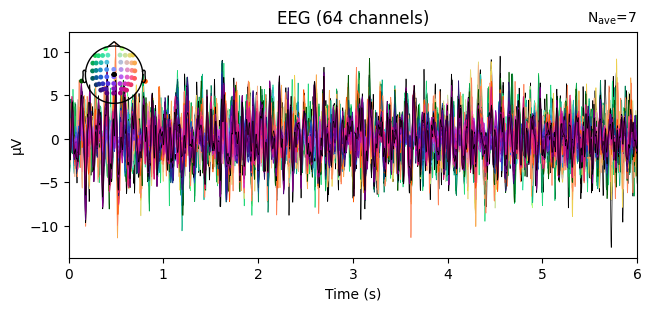

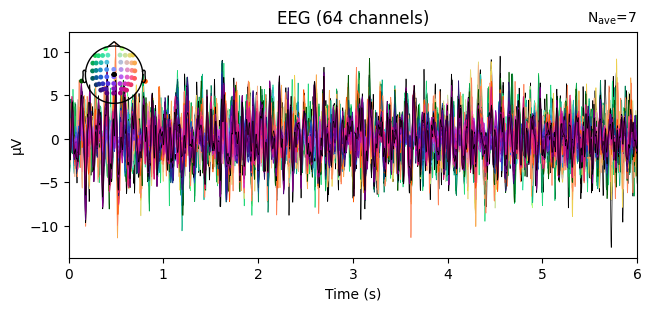

In [7]:
epochs['8'].average().plot(spatial_colors=True)